In [61]:
### Notebook to check the effect of disorder ina a simple single spin SNS hamiltonian in subband basis ###

In [62]:
import sys
import os

# Add the parent directory to sys.path
notebook_path = os.getcwd()  # Get the current working directory where the notebook is located
parent_directory = os.path.dirname(notebook_path)  # Move to the parent directory
sys.path.append(parent_directory)

# Now you can import config
from config import *
from Minimal_Model_2D import *
import time

np.set_printoptions(threshold=sys.maxsize)

In [63]:
class Minimal_Model_Subband_Basis(twoD_Minimal_Model):

    def Ham(self, dis_mag=0, uncorr_var=1, lmbda=0, seed=None, kx=0, ky=0, phi=0):

        M = bmat([
           [self.H_same_spin(dis_mag, uncorr_var, lmbda, seed, kx, ky ), self.Del_array(phi) ],
           [self.Del_array(phi).conjugate(),-self.H_same_spin(dis_mag, uncorr_var, lmbda, seed, -kx, -ky).conjugate() ]
       ]) 

        return M
    
    def U_dag_ph(self, my=1):

        M = bmat([
            [ self.U_dag(my), None],
            [None, -self.U_dag(my).conjugate()],
        ])

        return M
    
    def Ham_changed_basis(self,  dis_mag=0, uncorr_var=1, lmbda=0, seed=None, kx=0, ky=0, phi=0, my=1):

        S_dag = self.U_dag_ph(my)

        S = self.U_dag_ph(my).transpose().conjugate()

        H = self.Ham(dis_mag, uncorr_var, lmbda, seed, kx, ky,phi)

        return S_dag.dot(H).dot(S)

In [64]:
N = 3
NSM = 1 
NSC = 1            ### DOESNT' MATTER WHAT WE PTU N, NSSC, NSM AS ATLEAST FOR THIS NOTEBOOK  
M = 1
AX = 1
AY = 1 
#LY = (M//10)*AY
LY= 3*AY
MEFF_SC = 1 

#OMEGA =  2*4*hbm/LY**2/MEFF_SC

OMEGA=0

DELTA = 77

PHI = 0.5*np.pi

KNUM= 4 


A = Minimal_Model_Subband_Basis(N,NSM,NSC,M,AX,AY,OMEGA, delta=DELTA)

H = A.Ham(phi=PHI)

print(H.toarray().shape)

#E, V = eigsh(H , k = KNUM, sigma=0 )

(6, 6)


In [65]:
print(4*hbm)
print(H.toarray().round())

152.52956307360034
[[ 153. +0.j  -38. +0.j    0. +0.j   77. +0.j    0. +0.j    0. +0.j]
 [ -38. +0.j  153. +0.j  -38. +0.j    0. +0.j    0. +0.j    0. +0.j]
 [   0. +0.j  -38. +0.j  153. +0.j    0. +0.j    0. +0.j    0.+77.j]
 [  77. +0.j    0. +0.j    0. +0.j -153. +0.j   38. +0.j    0. +0.j]
 [   0. +0.j    0. +0.j    0. +0.j   38. +0.j -153. +0.j   38. +0.j]
 [   0. +0.j    0. +0.j    0.-77.j    0. +0.j   38. +0.j -153. +0.j]]


Change basis

In [66]:
N = 3
NSM = 1 
NSC = 1            ### DOESNT' MATTER WHAT WE PTU N, NSSC, NSM AS ATLEAST FOR THIS NOTEBOOK  
M = 1
AX = 1
AY = 1 
#LY = (M//10)*AY
LY= 3*AY
MEFF_SC = 1 

OMEGA=0

DELTA = 77

PHI = 0.5*np.pi

KNUM= 4 

A = Minimal_Model_Subband_Basis(N,NSM,NSC,M,AX,AY,OMEGA, delta=DELTA)

H = A.Ham(phi=PHI)

H_sb = A.Ham_changed_basis(phi=PHI ,my=3)

print(H_sb.toarray().shape)

(18, 18)


Finding eigenvalues and eigenvectors 
First for lmbda = 0 
then look at energy spectrum wrt lmbda 
then look at wavefunctions at different lmbdas 

In [68]:
NSM = 60            # number of sm x lattice points
M = 60              # should be atleast thrice confinement length
AX = 5              # lattice spacing in nm
AY = 5              # lattice spacing in nm
DELTA = 0.165       # in meV
MEFF_SC = 0.023     # proximitized InAs
MEFF_SM = 0.023     # InAs
NSC = 800
NTOT = 2*NSC + NSM
PHI = 0.5*np.pi 
#ALPHAT = 400        # meV-nm^3 # 20 is within perturbative regime for widths atleast up to 100 nm
K_NUM = 8           # No of eigenvalues needed to be found 
#W_MIN = 50

LY = 100           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC


print(OMEGA)

MU_SC =  0.8 + OMEGA/2   # in between two subbands
MU_SM =  0.8 + OMEGA/2   # in between two subbands

print(MU_SM)

UNCORR_VAR = 1167  ### uncorrelated variance of disorder

#LMBDA = np.array([0, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1,1])
#LMBDA = np.linspace(0.075, 0.2, 51)
#LMBDA = np.linspace(0.15, 0.21, 81)
LMBDA=0
SEED = 42  ## seed for the disorder 


A = Minimal_Model_Subband_Basis(NTOT,NSM,NSC,M,AX,AY,OMEGA, delta=DELTA, meff_sc=MEFF_SC, meff_sm=MEFF_SM, mu_sm = MU_SM, mu_sc=MU_SC)
H = A.Ham(phi=PHI)
E, V = eigsh(H ,k=K_NUM ,sigma=0, return_eigenvectors=True)

sorted_index = np.argsort(E)

Esorted = E[sorted_index]
Vsorted = V[:,sorted_index]

1.3263440267269595
1.4631720133634798


In [70]:
print(Esorted/DELTA)

[-1.03913388 -1.01431386 -1.00754878 -0.45813231  0.45813231  1.00754878
  1.01431386  1.03913388]


In [74]:
GS_WV = Vsorted[:,4].reshape(2,M,NTOT)

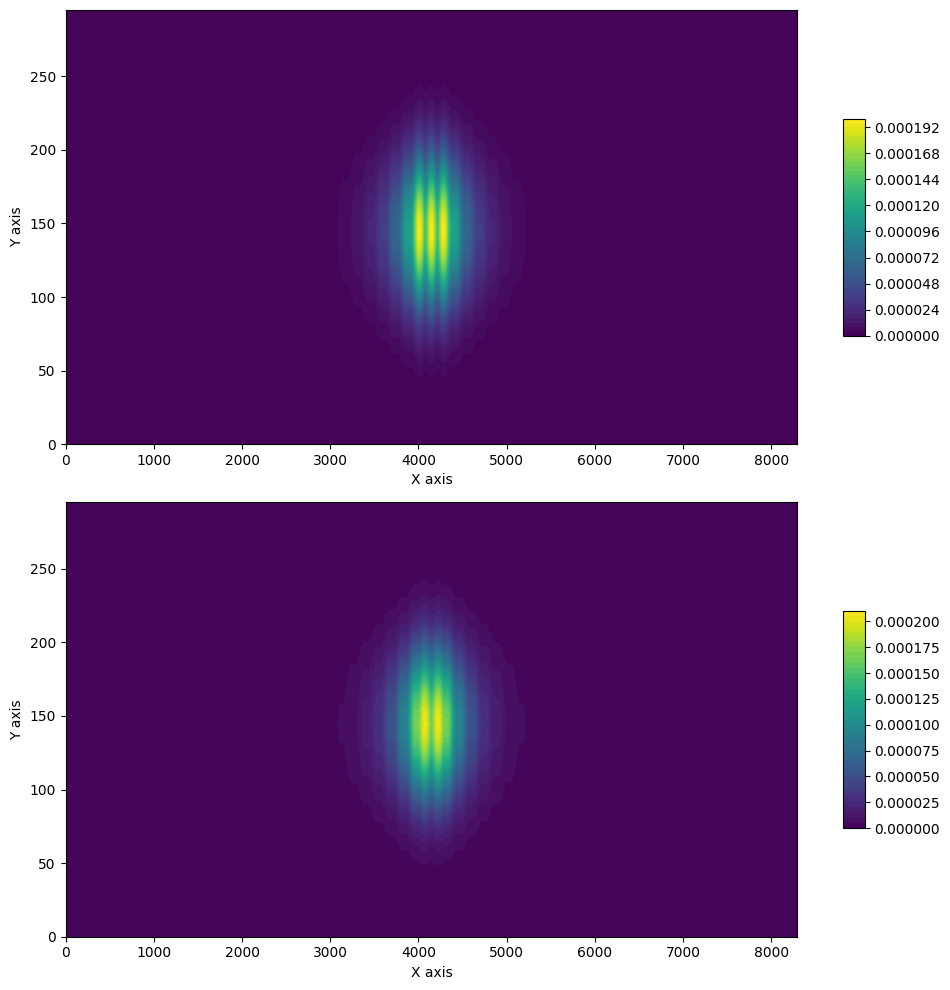

In [76]:
X = np.arange(NTOT)*AX

Y = np.arange(M)*AY

XM, YM = np.meshgrid(X,Y)

# Assuming XM and YM are meshgrids already created along with WV_ref_reshaped data
# You may need to redefine these or ensure they're available in your workspace

# Create a figure and a set of subplots in a 2x2 grid
fig, axes = plt.subplots(2, 1, figsize=(10, 10))

# Iterate over each subplot and plot the specific data
i = 0

for ax in np.nditer(axes, flags=['refs_ok']):
    # Get the current axis from the iterator
    ax = ax.item()

    # Select the appropriate slice of the WV_ref_reshaped data
    Z = np.abs(GS_WV[i%2, :, :])**2

    # Generate contour plot for the selected data slice
    contourf = ax.contourf(XM, YM, Z, 50, cmap='viridis')  # Using 50 levels for the contour
    
    # Set titles and labels
    #ax.set_title(f'Contour Plot ')
    ax.set_xlabel('X axis')
    ax.set_ylabel('Y axis')

    # Add a color bar specific to each subplot
    fig.colorbar(contourf, ax=ax, shrink=0.5, aspect=10)

    # Increment the index for selecting data slices
    i += 1

# Adjust layout to prevent overlap
plt.tight_layout()
plt.show()


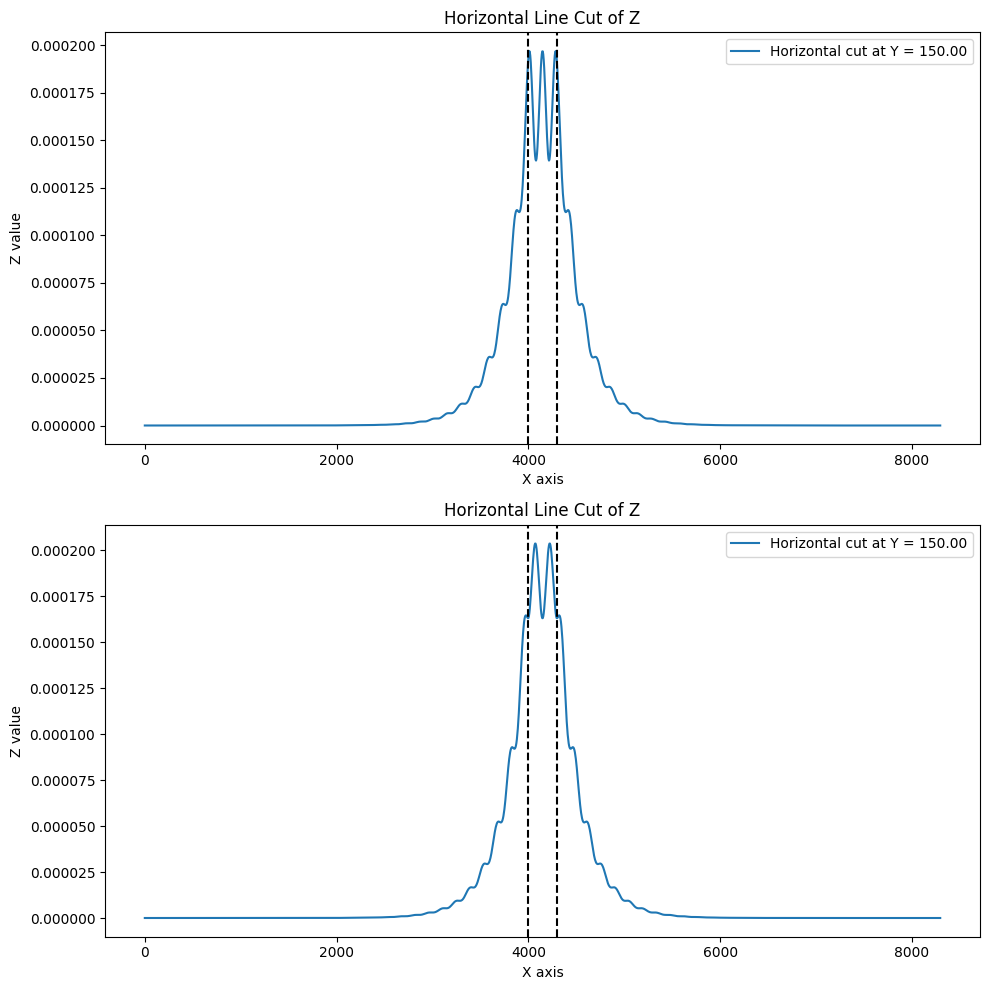

In [77]:
# Choose a specific index for the Y-axis
y_index = 30

# Create a figure and a set of subplots in a 2x2 grid
fig, axes = plt.subplots(2, 1, figsize=(10, 10))

# Iterate over each subplot and plot the same data
i = 0 
for ax in axes.flatten():

    Z = np.abs(GS_WV[i%2,:,:])**2
    # Extract the Z values at this Y index
    Z_line_cut = Z[y_index, :]
    ax.plot(XM[0, :], Z_line_cut, label=f'Horizontal cut at Y = {YM[ y_index,0]:.2f}')
    ax.axvline(x=NSC*AX, color='black', linestyle='dashed')
    ax.axvline(x=(NSC+NSM)*AX, color='black', linestyle='dashed')
    ax.legend()
    ax.set_xlabel('X axis')
    ax.set_ylabel('Z value')
    ax.set_title('Horizontal Line Cut of Z')

    i+=1

# Adjust layout to prevent overlap
plt.tight_layout()
plt.show()

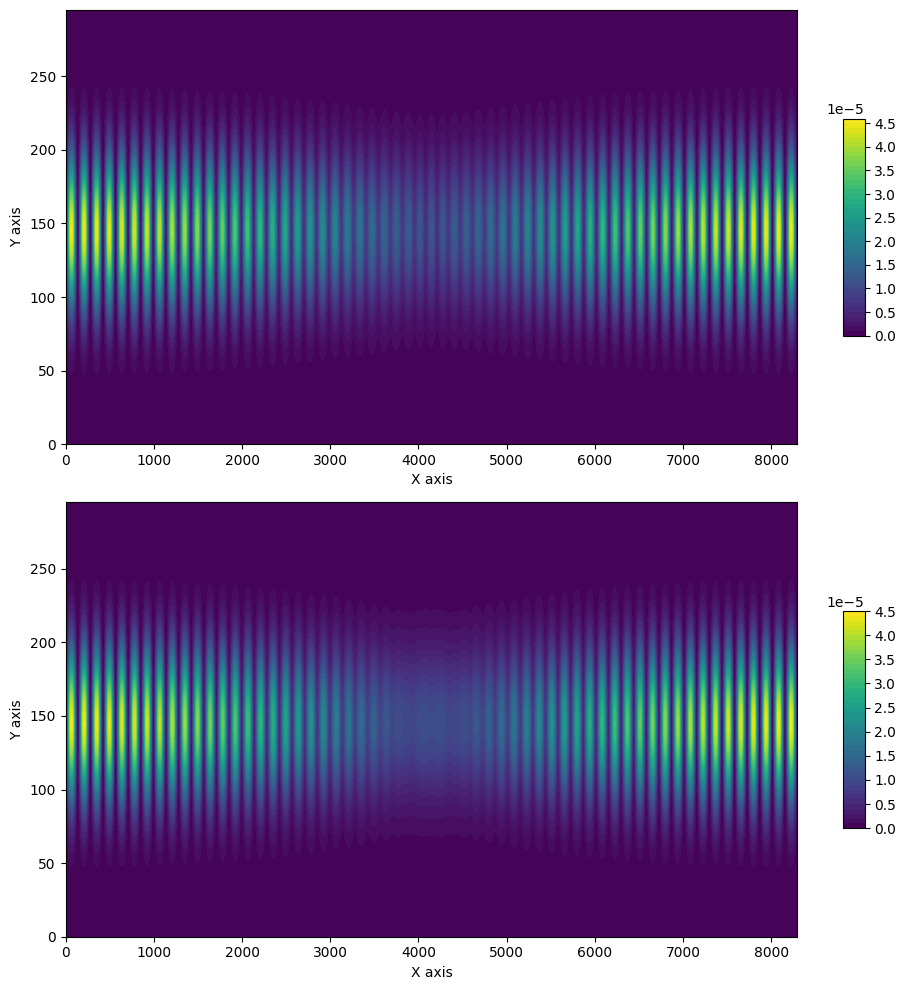

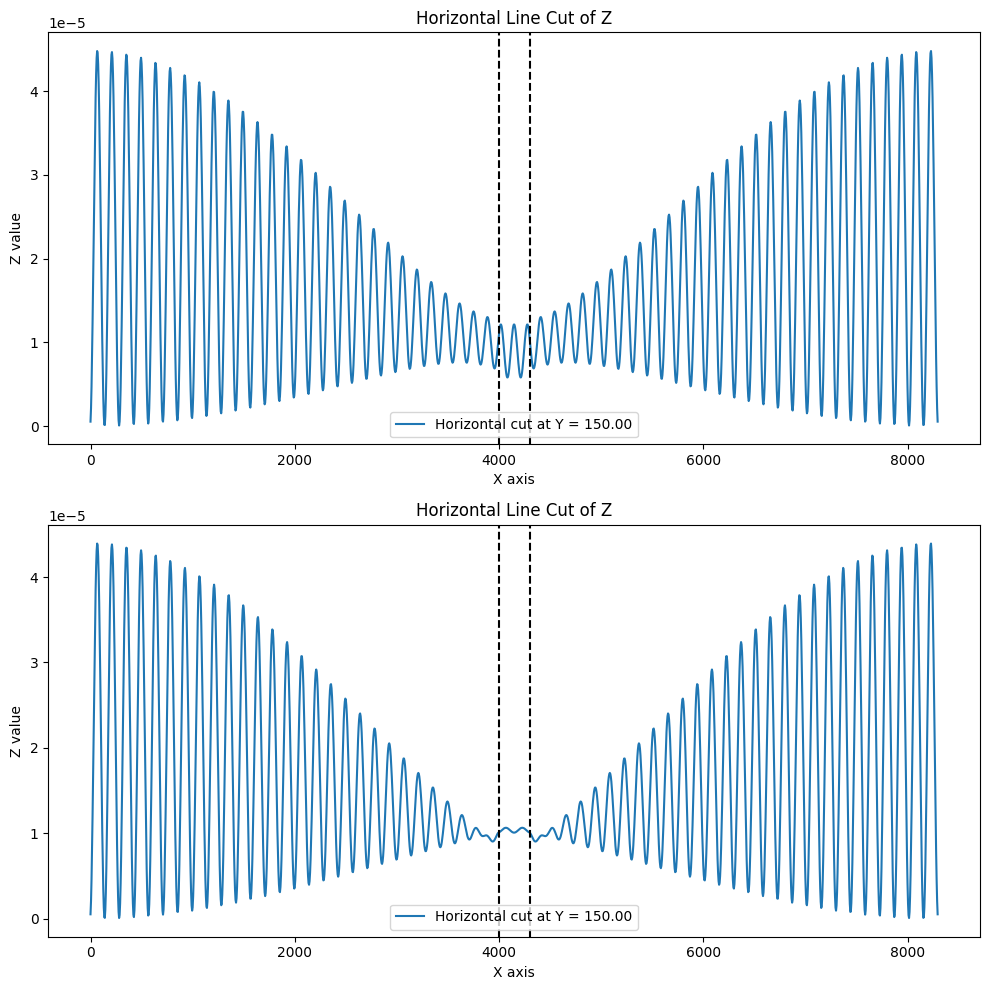

In [78]:
ES_WV = Vsorted[:,5].reshape(2,M,NTOT)
X = np.arange(NTOT)*AX

Y = np.arange(M)*AY

XM, YM = np.meshgrid(X,Y)

# Assuming XM and YM are meshgrids already created along with WV_ref_reshaped data
# You may need to redefine these or ensure they're available in your workspace

# Create a figure and a set of subplots in a 2x2 grid
fig, axes = plt.subplots(2, 1, figsize=(10, 10))

# Iterate over each subplot and plot the specific data
i = 0

for ax in np.nditer(axes, flags=['refs_ok']):
    # Get the current axis from the iterator
    ax = ax.item()

    # Select the appropriate slice of the WV_ref_reshaped data
    Z = np.abs(ES_WV[i%2, :, :])**2

    # Generate contour plot for the selected data slice
    contourf = ax.contourf(XM, YM, Z, 50, cmap='viridis')  # Using 50 levels for the contour
    
    # Set titles and labels
    #ax.set_title(f'Contour Plot ')
    ax.set_xlabel('X axis')
    ax.set_ylabel('Y axis')

    # Add a color bar specific to each subplot
    fig.colorbar(contourf, ax=ax, shrink=0.5, aspect=10)

    # Increment the index for selecting data slices
    i += 1

# Adjust layout to prevent overlap
plt.tight_layout()
plt.show()

# Choose a specific index for the Y-axis
y_index = 30

# Create a figure and a set of subplots in a 2x2 grid
fig, axes = plt.subplots(2, 1, figsize=(10, 10))

# Iterate over each subplot and plot the same data
i = 0 
for ax in axes.flatten():

    Z = np.abs(ES_WV[i%2,:,:])**2
    # Extract the Z values at this Y index
    Z_line_cut = Z[y_index, :]
    ax.plot(XM[0, :], Z_line_cut, label=f'Horizontal cut at Y = {YM[ y_index,0]:.2f}')
    ax.axvline(x=NSC*AX, color='black', linestyle='dashed')
    ax.axvline(x=(NSC+NSM)*AX, color='black', linestyle='dashed')
    ax.legend()
    ax.set_xlabel('X axis')
    ax.set_ylabel('Z value')
    ax.set_title('Horizontal Line Cut of Z')

    i+=1

# Adjust layout to prevent overlap
plt.tight_layout()
plt.show()


PLOTTING ENERGY SPECTRUM VS LMBDA

In [80]:
#LMBDA = np.linspace(0.075, 0.2, 51)

NSM = 60            # number of sm x lattice points
M = 60              # should be atleast thrice confinement length
AX = 5              # lattice spacing in nm
AY = 5              # lattice spacing in nm
DELTA = 0.165       # in meV
MEFF_SC = 0.023     # proximitized InAs
MEFF_SM = 0.023     # InAs
NSC = 800
NTOT = 2*NSC + NSM
PHI = 0.5*np.pi 
#ALPHAT = 400        # meV-nm^3 # 20 is within perturbative regime for widths atleast up to 100 nm
K_NUM = 8           # No of eigenvalues needed to be found 
#W_MIN = 50

LY = 100           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC


print(OMEGA)

MU_SC =  0.8 + OMEGA/2   # in between two subbands
MU_SM =  0.8 + OMEGA/2   # in between two subbands

print(MU_SM)

UNCORR_VAR = 1167  ### uncorrelated variance of disorder

#LMBDA = np.array([0, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1,1])
LMBDA = np.linspace(0.075, 0.25, 51)
#LMBDA = np.linspace(0.15, 0.21, 81)
#LMBDA=0
SEED = 42  ## seed for the disorder 

Ep = np.empty((LMBDA.shape[0],K_NUM))

for i in range(LMBDA.shape[0]):

    t1 = time.time()

    
    A = Minimal_Model_Subband_Basis(NTOT,NSM,NSC,M,AX,AY,OMEGA, delta=DELTA, meff_sc=MEFF_SC, meff_sm=MEFF_SM, mu_sm = MU_SM, mu_sc=MU_SC)
    H = A.Ham(uncorr_var=UNCORR_VAR, lmbda=LMBDA[i], seed=SEED, phi=PHI)
    E = eigsh(H ,k=K_NUM ,sigma=0, return_eigenvectors=False)

    Esorted = np.sort(E)

    Ep[i,:] = Esorted/DELTA

    t2 = time.time()

    print("sample no. {}".format(i), "time: ", round(t2-t1), "lmbda: ", LMBDA[i])

    #print(Ep[i,:])


np.save('Ep_no_soc_one_spin_vs_lmbda_{:.2f}_to_{:.2f}.npy'.format(LMBDA[0],LMBDA[-1]),Ep)

1.3263440267269595
1.4631720133634798
sample no. 0 time:  36 lmbda:  0.075
sample no. 1 time:  35 lmbda:  0.0785
sample no. 2 time:  35 lmbda:  0.08199999999999999
sample no. 3 time:  36 lmbda:  0.08549999999999999
sample no. 4 time:  35 lmbda:  0.089
sample no. 5 time:  37 lmbda:  0.0925
sample no. 6 time:  41 lmbda:  0.096
sample no. 7 time:  42 lmbda:  0.09949999999999999
sample no. 8 time:  41 lmbda:  0.103
sample no. 9 time:  39 lmbda:  0.1065
sample no. 10 time:  42 lmbda:  0.10999999999999999
sample no. 11 time:  42 lmbda:  0.11349999999999999
sample no. 12 time:  43 lmbda:  0.11699999999999999
sample no. 13 time:  39 lmbda:  0.1205
sample no. 14 time:  38 lmbda:  0.124
sample no. 15 time:  40 lmbda:  0.1275
sample no. 16 time:  38 lmbda:  0.131
sample no. 17 time:  37 lmbda:  0.1345
sample no. 18 time:  37 lmbda:  0.138
sample no. 19 time:  39 lmbda:  0.1415
sample no. 20 time:  42 lmbda:  0.145
sample no. 21 time:  41 lmbda:  0.1485
sample no. 22 time:  47 lmbda:  0.1519999999

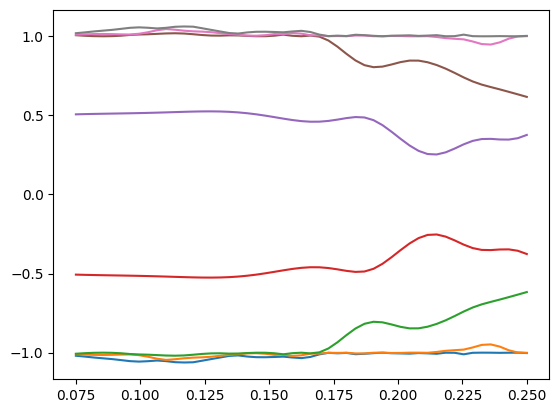

In [82]:
plt.plot(LMBDA, Ep)